**Implementation and Comparison of Decision Tree Regression and Random Forest Regression for House Price Prediction**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load California Housing dataset
data = fetch_california_housing(as_frame=True)

X = data.data.copy()
y = data.target.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Input features:", list(X.columns))
print("Target: Median House Value (in $100,000 units)")

display(data.frame.head())

Dataset loaded successfully!
Dataset shape: (20640, 8)
Input features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: Median House Value (in $100,000 units)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
print("Dataset information:")
X.info()

print("\nMissing values in each feature:")
print(X.isnull().sum())

print("\nDuplicate rows:", X.duplicated().sum())

print("\nSummary statistics:")
display(X.describe())

print("\nMissing target values:", y.isnull().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB

Missing values in each feature:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

Duplicate rows: 0

Summary statistics:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000



Missing target values: 0


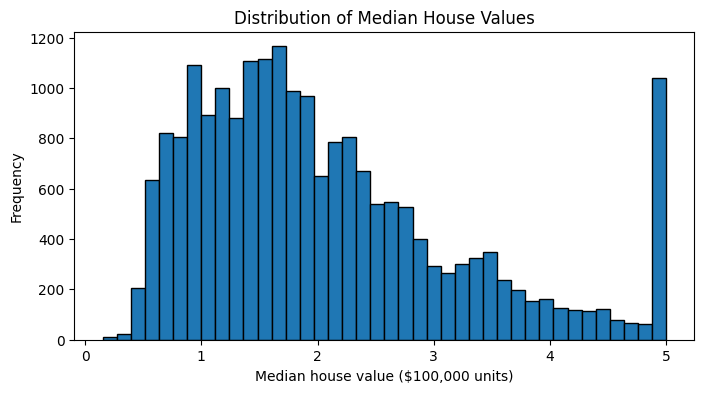

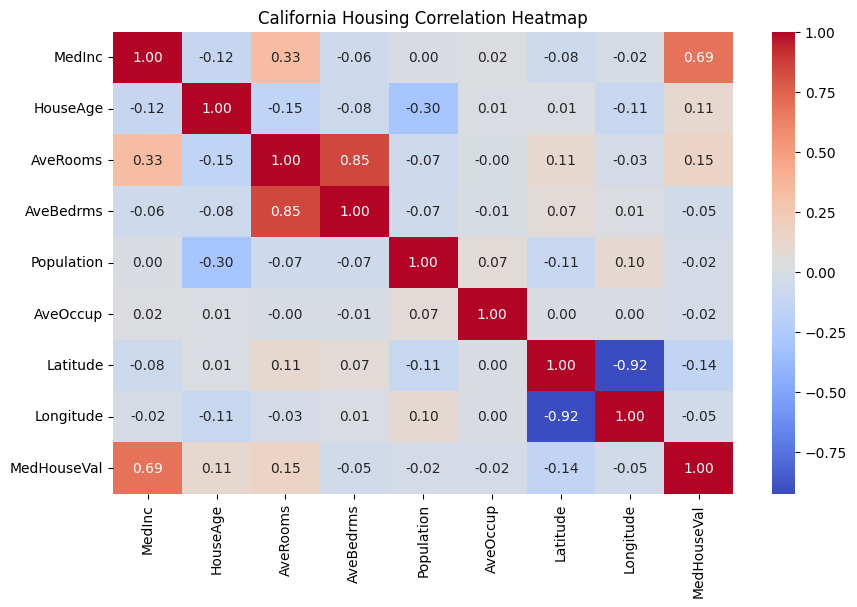

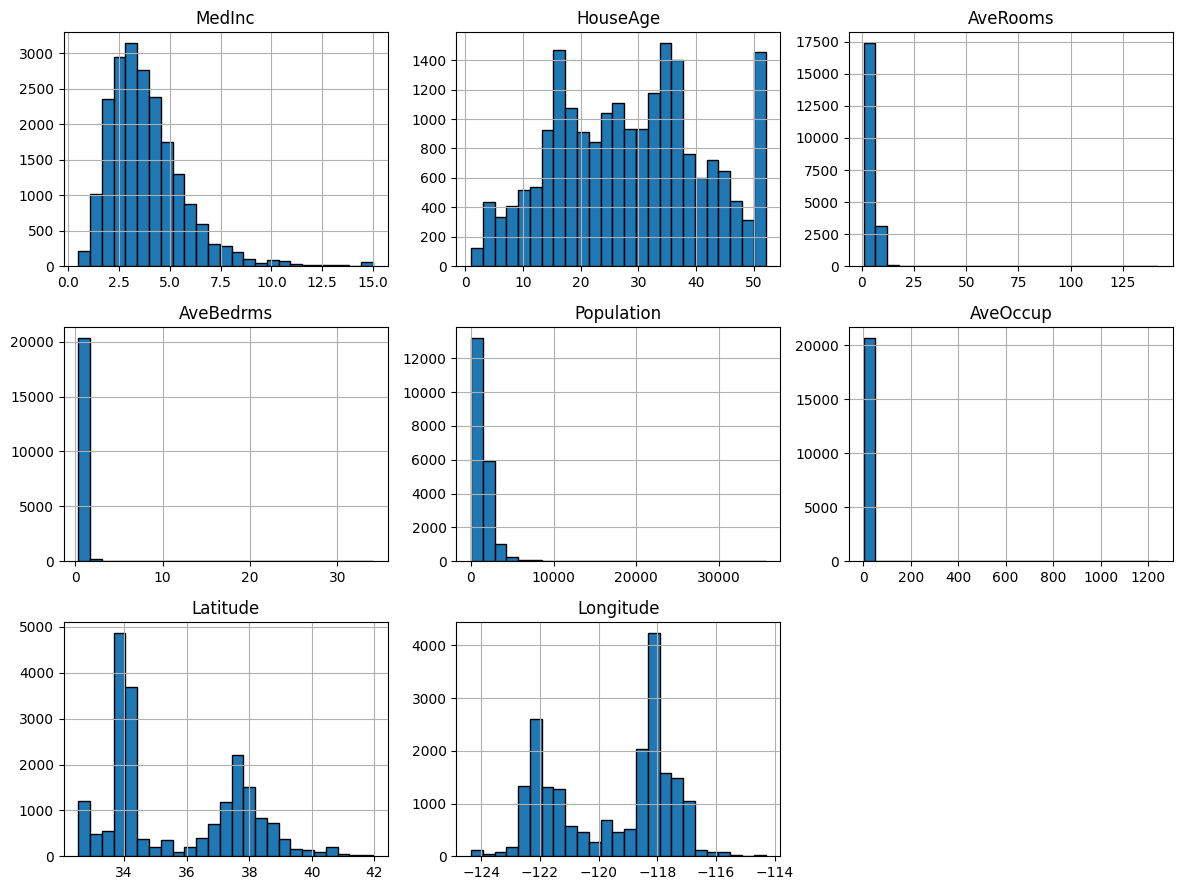

In [ ]:
# Plot median house value distribution
plt.figure(figsize=(8, 4))
plt.hist(y, bins=40, edgecolor="black")
plt.title("Distribution of Median House Values")
plt.xlabel("Median house value ($100,000 units)")
plt.ylabel("Frequency")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(data.frame.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("California Housing Correlation Heatmap")
plt.show()

# Feature distributions
X.hist(figsize=(12, 9), bins=25, edgecolor="black")
plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


Selected six features:
MedInc
AveOccup
Latitude
Longitude
HouseAge
AveRooms


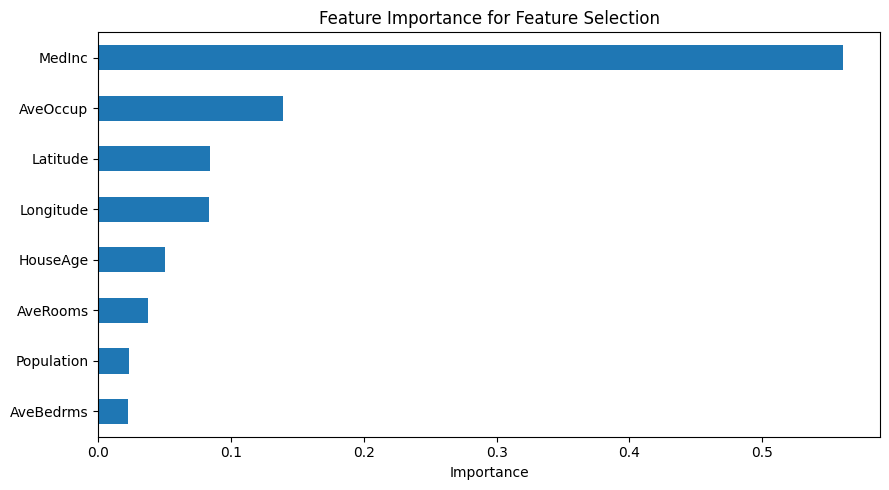


Selected training shape: (16512, 6)
Selected testing shape: (4128, 6)


In [ ]:
selector_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_train, y_train)

importance = pd.Series(
    selector_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

selected_features = importance.head(6).index.tolist()

print("Selected six features:")
for feature in selected_features:
    print(feature)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Feature Importance for Feature Selection")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# Use the same selected features for both models
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("\nSelected training shape:", X_train_selected.shape)
print("Selected testing shape:", X_test_selected.shape)

In [ ]:
dt_model = DecisionTreeRegressor(
    max_depth=6,
    min_samples_leaf=10,
    random_state=42
)

dt_model.fit(X_train_selected, y_train)

dt_pred = dt_model.predict(X_test_selected)

print("Decision Tree Regressor trained!")

Decision Tree Regressor trained!


In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_selected, y_train)

rf_pred = rf_model.predict(X_test_selected)

print("Random Forest Regressor trained!")

Random Forest Regressor trained!


In [ ]:
def evaluate_model(name, actual, predicted):
    return {
        "Algorithm": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    evaluate_model("Decision Tree", y_test, dt_pred),
    evaluate_model("Random Forest", y_test, rf_pred)
])

results[["MAE", "RMSE", "R2 Score"]] = results[
    ["MAE", "RMSE", "R2 Score"]
].round(4)

display(results)

print("Note: House values and MAE/RMSE are in $100,000 units.")

,Algorithm,MAE,RMSE,R2 Score
0,Decision Tree,0.4991,0.7025,0.6234
1,Random Forest,0.3209,0.5026,0.8072


Note: House values and MAE/RMSE are in $100,000 units.


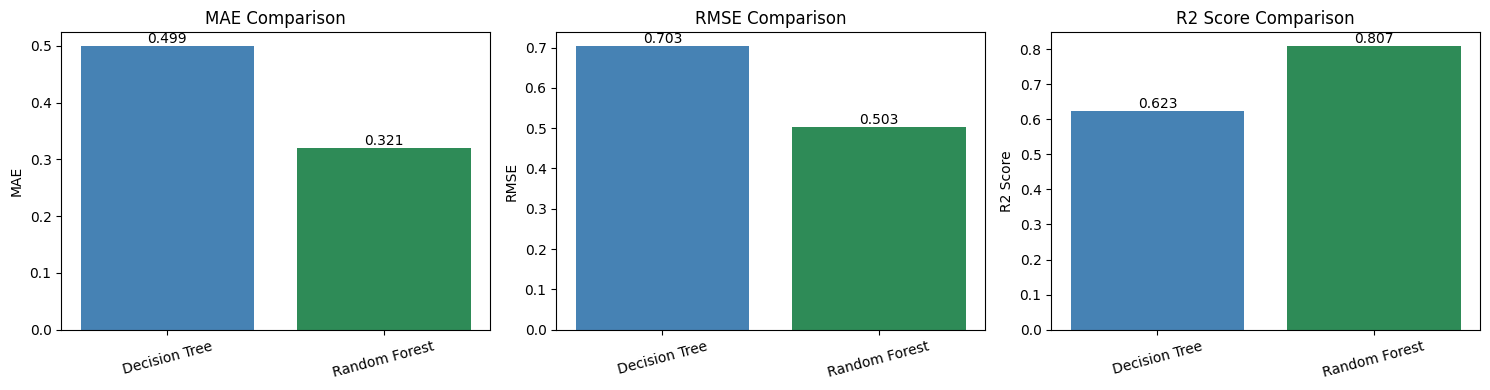

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ["MAE", "RMSE", "R2 Score"]
colors = ["steelblue", "seagreen"]

for i, metric in enumerate(metrics):
    axes[i].bar(results["Algorithm"], results[metric], color=colors)
    axes[i].set_title(metric + " Comparison")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis="x", rotation=15)

    for j, value in enumerate(results[metric]):
        axes[i].text(j, value, f"{value:.3f}",
                     ha="center", va="bottom")

plt.tight_layout()
plt.show()

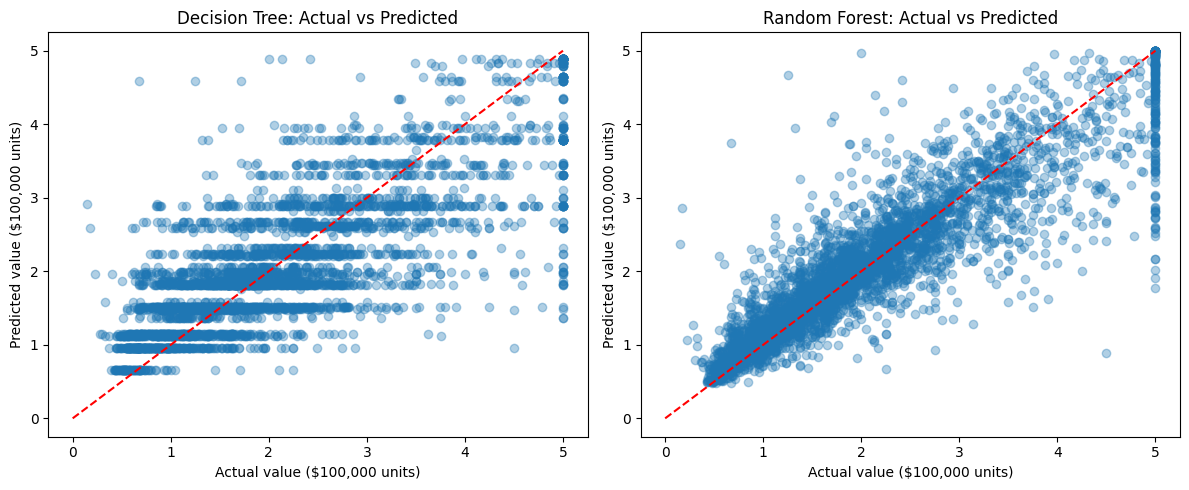

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, dt_pred, alpha=0.35)
axes[0].plot([0, 5], [0, 5], "r--")
axes[0].set_title("Decision Tree: Actual vs Predicted")
axes[0].set_xlabel("Actual value ($100,000 units)")
axes[0].set_ylabel("Predicted value ($100,000 units)")

axes[1].scatter(y_test, rf_pred, alpha=0.35)
axes[1].plot([0, 5], [0, 5], "r--")
axes[1].set_title("Random Forest: Actual vs Predicted")
axes[1].set_xlabel("Actual value ($100,000 units)")
axes[1].set_ylabel("Predicted value ($100,000 units)")

plt.tight_layout()
plt.show()

In [ ]:
dt_r2 = r2_score(y_test, dt_pred)
rf_r2 = r2_score(y_test, rf_pred)

dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("DECISION TREE R2 SCORE:", round(dt_r2, 4))
print("RANDOM FOREST R2 SCORE:", round(rf_r2, 4))

print("\nDECISION TREE RMSE:", round(dt_rmse, 4))
print("RANDOM FOREST RMSE:", round(rf_rmse, 4))

if rf_r2 > dt_r2 and rf_rmse < dt_rmse:
    print("\nConclusion: Random Forest performs better on both R2 and RMSE.")
elif rf_r2 > dt_r2:
    print("\nConclusion: Random Forest has a higher R2 score.")
elif rf_rmse < dt_rmse:
    print("\nConclusion: Random Forest has a lower RMSE.")
else:
    print("\nConclusion: Compare all metrics; neither model wins on both measures.")

DECISION TREE R2 SCORE: 0.6234
RANDOM FOREST R2 SCORE: 0.8072

DECISION TREE RMSE: 0.7025
RANDOM FOREST RMSE: 0.5026

Conclusion: Random Forest performs better on both R2 and RMSE.


In [ ]:
sample = X_test_selected.iloc[[0]]

dt_value = dt_model.predict(sample)[0]
rf_value = rf_model.predict(sample)[0]
actual_value = y_test.iloc[0]

print("Sample input:")
display(sample)

print(f"Actual median value: ${actual_value * 100000:,.2f}")
print(f"Decision Tree prediction: ${dt_value * 100000:,.2f}")
print(f"Random Forest prediction: ${rf_value * 100000:,.2f}")

Sample input:


,MedInc,AveOccup,Latitude,Longitude,HouseAge,AveRooms
20046,1.6812,3.877437,36.06,-119.01,25.0,4.192201


Actual median value: $47,700.00
Decision Tree prediction: $111,480.88
Random Forest prediction: $48,225.16


In [ ]:
joblib.dump(dt_model, "decision_tree_regressor.pkl")
joblib.dump(rf_model, "random_forest_regressor.pkl")

metadata = {
    "features": selected_features,
    "defaults": X_train_selected.median().to_dict()
}

joblib.dump(metadata, "housing_metadata.pkl")

# Save the source dataset as CSV for submission
data.frame.to_csv("california_housing_dataset.csv", index=False)

# Save evaluation results
results.to_csv("regression_results.csv", index=False)

print("Models, metadata, dataset and results saved successfully!")

Models, metadata, dataset and results saved successfully!


In [ ]:
files.download("decision_tree_regressor.pkl")
files.download("random_forest_regressor.pkl")
files.download("housing_metadata.pkl")
files.download("california_housing_dataset.csv")
files.download("regression_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>